# Multi-label news classification

A three-input neural network predicts 18 semantic labels from news text, Bag-of-Words counts and publication metadata. The dataset contains 11,000 entries, with two or three labels per entry. This deep-learning project covers input preparation, architecture design, regularization, validation-based selection and held-out evaluation.

Run the notebook from top to bottom. Place the dataset `input_data.pkl` in `data/` locally or upload it to the Colab working directory. The dataset is not included in this repository. Only load the trusted original file: pickle files can execute code.

In [1]:
import os
import time
import string
import json
import pickle as pk
import hashlib
import platform
import shutil
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             multilabel_confusion_matrix)
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Dense, Dropout, Embedding, LSTM,
                                    Bidirectional, Concatenate, BatchNormalization, Activation)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

REPORT_DIR = Path('reports')
REPORT_DIR.mkdir(exist_ok=True)
run_start = time.perf_counter()

In [2]:
SEED = 213

def setRandomSeed(seed):
    tf.keras.utils.set_random_seed(seed)

setRandomSeed(SEED)

In [3]:
PKL_PATH = next((p for p in [Path('data/input_data.pkl'), Path('input_data.pkl')]
                 if p.is_file()), None)
if PKL_PATH is None:
    raise FileNotFoundError('Place the trusted input_data.pkl in data/ or the notebook directory, then rerun.')
with PKL_PATH.open('rb') as f:
    data = pk.load(f)
texts = data['texts']
years = np.asarray(data['years'])
months = np.asarray(data['months'])
X_bow = data['X_bow']
Y = np.asarray(data['labels'])
assert X_bow.shape == (len(texts), 10000) and Y.shape == (len(texts), 18)
assert all(isinstance(t, str) and t.strip() for t in texts)
assert len(years) == len(months) == len(texts)
assert np.isin(Y, [0, 1]).all() and np.isfinite(X_bow).all() and (X_bow >= 0).all()
assert np.isfinite(years).all() and np.isin(months, np.arange(1, 13)).all()
print('Samples:', len(texts), '| BoW:', X_bow.shape, '| Labels:', Y.shape)
print('Labels per article:', np.unique(Y.sum(axis=1), return_counts=True))
print('Positive examples per label:', Y.sum(axis=0))

Samples: 11000 | BoW: (11000, 10000) | Labels: (11000, 18)
Labels per article: (array([2, 3]), array([8000, 3000]))
Positive examples per label: [1000 1000 1000 1000 1000 1000 1000 2000 1000 4000 2000 1000 2000 1000
 1000 1000 1000 2000]


## 1. MODEL CHOICE

Each article can have several labels, so the network uses independent sigmoid outputs. A text branch uses a learned Embedding and Bidirectional LSTM to represent word order; a Dense branch represents the supplied 10,000-dimensional Bag-of-Words counts; another Dense branch represents publication year and month. Concatenation combines the three representations before the prediction head.

```text
Text IDs [B,100] → masked Embedding → Bidirectional LSTM ─┐
BoW counts [B,10000] → Dense → BatchNorm → ReLU → Dropout ├→ Concatenate
Year/month [B,2] → Dense → BatchNorm → ReLU → Dropout ────┘
      → Dense → BatchNorm → ReLU → Dropout (twice) → 18 sigmoids
```

The two text representations overlap in information; the architecture can combine them, but their individual contribution is not established by this experiment.

## 2. INPUT

**a. Preprocessing.** Split news into training, validation and test before fitting the text vocabulary or metadata scaler. Keep identical texts (after lowercasing and whitespace normalization) in the same split. GroupShuffleSplit targets 70/15/15 proportions; group sizes can cause small differences in the counts. No labels determine the split. Report each split's label prevalence below.

Lowercase text, strip punctuation and retain alphabetic words. Learn at most 10,000 words from training only. Reserve ID 0 for padding and ID 1 for unknown words, so unknown words remain visible to the LSTM. Post-pad or truncate to 100 tokens. `mask_zero=True` makes the LSTM ignore padding. Standardize year and month using training statistics. Month is represented numerically, without modeling its annual cycle.

**b. Tensors.** Text: integer IDs `[B,100]`; BoW: nonnegative float32 counts `[B,10000]`; metadata: standardized float32 values `[B,2]`; targets: binary indicators `[B,18]`.

The supplied BoW representation uses a vocabulary extracted from the entire collection, rather than solely from the training split. A fresh inductive evaluation would rebuild it from training texts. This random grouped split evaluates held-out entries from this collection, not future years or another news source.

In [4]:
N_CLASSES = Y.shape[1]
VOCAB_SIZE = 10000
MAX_TEXT_LEN = 100
indices = np.arange(len(texts))
groups = np.asarray([' '.join(t.lower().split()) for t in texts])
train_idx, temp_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.30,
                          random_state=SEED).split(indices, groups=groups))
val_pos, test_pos = next(GroupShuffleSplit(n_splits=1, test_size=0.50,
                         random_state=SEED).split(temp_idx, groups=groups[temp_idx]))
val_idx, test_idx = temp_idx[val_pos], temp_idx[test_pos]
assert len(set(train_idx) | set(val_idx) | set(test_idx)) == len(texts)
for a, b in [(train_idx, val_idx), (train_idx, test_idx), (val_idx, test_idx)]:
    assert not set(groups[a]) & set(groups[b])
prevalence = pd.DataFrame({name: Y[idx].mean(axis=0)
    for name, idx in [('train', train_idx), ('validation', val_idx), ('test', test_idx)]})
assert (prevalence > 0).all().all(), 'Every label must occur in each split.'
print('Train / validation / test:', len(train_idx), len(val_idx), len(test_idx))
print('Repeated entries beyond first occurrence:', len(texts) - len(set(groups)))
prevalence.to_csv(REPORT_DIR / 'label_prevalence.csv', index_label='label_id')
split_names = np.empty(len(texts), dtype=object)
for name, idx in [('train',train_idx),('validation',val_idx),('test',test_idx)]: split_names[idx] = name
pd.DataFrame({'row_id': indices, 'split': split_names}).to_csv(REPORT_DIR / 'split_assignments.csv', index=False)
prevalence

Train / validation / test: 7705 1647 1648
Repeated entries beyond first occurrence: 19


,train,validation,test
0,0.090201,0.098968,0.086165
1,0.092278,0.085610,0.089806
2,0.090201,0.098968,0.086165
3,0.092278,0.085610,0.089806
4,0.091369,0.086825,0.092840
5,0.090201,0.098968,0.086165
6,0.087735,0.086825,0.109830
7,0.182738,0.187007,0.172330
8,0.091110,0.083789,0.097087
9,0.358988,0.363084,0.385922


In [5]:
def get_words(text):
    text = text.replace("--", " ")
    words = text.split()
    table = str.maketrans("", "", string.punctuation)
    words = [w.translate(table) for w in words]
    words = [word for word in words if word.isalpha()]
    words = [word.lower() for word in words]
    return words

def build_word_dict(train_texts, vocab_size):
    counter = Counter()
    for text in train_texts:
        counter.update(get_words(text))

    most_common_words = [word for word, _ in counter.most_common(vocab_size)]
    return {word: idx + 2 for idx, word in enumerate(most_common_words)}

def texts_to_padded_sequences(input_texts, word_dict, max_len):
    X = np.zeros((len(input_texts), max_len), dtype="int32")
    for i, text in enumerate(input_texts):
        words = get_words(text)
        for t, word in enumerate(words[:max_len]):
            X[i, t] = word_dict.get(word, 1)
    return X

train_texts = [texts[i] for i in train_idx]
val_texts = [texts[i] for i in val_idx]
test_texts = [texts[i] for i in test_idx]

word_dict = build_word_dict(train_texts, VOCAB_SIZE)

X_text_train = texts_to_padded_sequences(train_texts, word_dict, MAX_TEXT_LEN)
X_text_val = texts_to_padded_sequences(val_texts, word_dict, MAX_TEXT_LEN)
X_text_test = texts_to_padded_sequences(test_texts, word_dict, MAX_TEXT_LEN)

print("Text train shape:", X_text_train.shape)
print("Vocabulary size used:", len(word_dict))

# Small checks for the preprocessing contract.
assert texts_to_padded_sequences(['known unseen'], {'known': 2}, 4).tolist() == [[2, 1, 0, 0]]
assert texts_to_padded_sequences(['known known known'], {'known': 2}, 2).tolist() == [[2, 2]]
assert get_words('Hello, WORLD! 123') == ['hello', 'world']

Text train shape: (7705, 100)
Vocabulary size used: 10000


In [6]:
X_bow_train = X_bow[train_idx].astype("float32")
X_bow_val = X_bow[val_idx].astype("float32")
X_bow_test = X_bow[test_idx].astype("float32")

metadata = np.column_stack([years, months]).astype("float32")

metadata_train = metadata[train_idx]
metadata_val = metadata[val_idx]
metadata_test = metadata[test_idx]

metadata_scaler = StandardScaler()
X_meta_train = metadata_scaler.fit_transform(metadata_train).astype("float32")
X_meta_val = metadata_scaler.transform(metadata_val).astype("float32")
X_meta_test = metadata_scaler.transform(metadata_test).astype("float32")

Y_train = Y[train_idx].astype("float32")
Y_val = Y[val_idx].astype("float32")
Y_test = Y[test_idx].astype("int32")

print("BoW train shape:", X_bow_train.shape)
print("Metadata train shape:", X_meta_train.shape)
print("Y train shape:", Y_train.shape)


BoW train shape: (7705, 10000)
Metadata train shape: (7705, 2)
Y train shape: (7705, 18)


## 3. OUTPUT AND LOSS

The output is `[B,18]`, with one sigmoid probability per label. Binary cross-entropy averages the 18 binary classification losses. Multiple labels may be positive simultaneously. A global threshold converts probabilities into labels; it is selected using validation data after choosing the network.

## 4. MODEL CONFIGURATION

**a. Composition.** The network follows the three-branch diagram above, with two Dense fusion layers and independent sigmoid outputs. Batch normalization stabilizes intermediate activations; dropout and L2 on the high-dimensional BoW Dense kernel control fitting capacity. Adam uses a learning rate of 0.001 and gradient clipping for recurrent training.

**b. Validation procedure.** Compare four bounded configurations, each for at most 10 epochs with the same batch size and seed. Early stopping monitors validation loss (binary cross-entropy plus the L2 penalty), uses patience 2 and restores the best weights. Evaluate restored checkpoints at threshold 0.5, reporting training and validation macro-F1 together.

Among candidates within 0.02 validation macro-F1 of the highest score, choose the smallest absolute training/validation gap, breaking ties by fewer parameters. This declared tolerance permits a modest performance tradeoff for regularization; a small gap alone would also reward underfitting. Validation estimates can be optimistic after these choices. Reuse the selected checkpoint without retraining.

In [7]:
TUNING_CONFIGS = [{'name': 'small_regularized',
  'embedding_dim': 64,
  'lstm_units': 64,
  'bow_units': 128,
  'meta_units': 64,
  'dense_units_1': 128,
  'dense_units_2': 64,
  'dropout_rate_1': 0.3,
  'dropout_rate_2': 0.2,
  'learning_rate': 0.001,
  'l2_strength': 0.0001},
 {'name': 'base',
  'embedding_dim': 64,
  'lstm_units': 128,
  'bow_units': 128,
  'meta_units': 64,
  'dense_units_1': 128,
  'dense_units_2': 64,
  'dropout_rate_1': 0.3,
  'dropout_rate_2': 0.2,
  'learning_rate': 0.001,
  'l2_strength': 0.0},
 {'name': 'stronger_dropout',
  'embedding_dim': 64,
  'lstm_units': 64,
  'bow_units': 128,
  'meta_units': 64,
  'dense_units_1': 128,
  'dense_units_2': 64,
  'dropout_rate_1': 0.45,
  'dropout_rate_2': 0.35,
  'learning_rate': 0.001,
  'l2_strength': 0.0},
 {'name': 'dropout_with_l2',
  'embedding_dim': 64,
  'lstm_units': 64,
  'bow_units': 128,
  'meta_units': 64,
  'dense_units_1': 128,
  'dense_units_2': 64,
  'dropout_rate_1': 0.45,
  'dropout_rate_2': 0.35,
  'learning_rate': 0.001,
  'l2_strength': 0.001}]

def create_model(config):
    text_input = Input(shape=(MAX_TEXT_LEN,), name="text_input")
    text_branch = Embedding(
        input_dim=VOCAB_SIZE + 2,
        output_dim=config["embedding_dim"],
        mask_zero=True,
        name="text_embedding",
    )(text_input)
    text_branch = Bidirectional(
        LSTM(units=config["lstm_units"]),
        name="bidirectional_lstm",
    )(text_branch)

    bow_input = Input(shape=(X_bow_train.shape[1],), name="bow_input")
    bow_branch = Dense(config["bow_units"], activation=None, kernel_regularizer=tf.keras.regularizers.l2(config["l2_strength"]), name="bow_dense")(bow_input)
    bow_branch = BatchNormalization(name="bow_batch_norm")(bow_branch)
    bow_branch = Activation("relu", name="bow_relu")(bow_branch)
    bow_branch = Dropout(config["dropout_rate_1"], name="bow_dropout")(bow_branch)

    metadata_input = Input(shape=(X_meta_train.shape[1],), name="metadata_input")
    metadata_branch = Dense(config["meta_units"], activation=None, name="metadata_dense")(metadata_input)
    metadata_branch = BatchNormalization(name="metadata_batch_norm")(metadata_branch)
    metadata_branch = Activation("relu", name="metadata_relu")(metadata_branch)
    metadata_branch = Dropout(config["dropout_rate_1"], name="metadata_dropout")(metadata_branch)

    combined = Concatenate(name="concatenate_inputs")([
        text_branch,
        bow_branch,
        metadata_branch,
    ])

    hidden = Dense(config["dense_units_1"], activation=None, name="combined_dense_1")(combined)
    hidden = BatchNormalization(name="combined_batch_norm_1")(hidden)
    hidden = Activation("relu", name="combined_relu_1")(hidden)
    hidden = Dropout(config["dropout_rate_1"], name="combined_dropout_1")(hidden)

    hidden = Dense(config["dense_units_2"], activation=None, name="combined_dense_2")(hidden)
    hidden = BatchNormalization(name="combined_batch_norm_2")(hidden)
    hidden = Activation("relu", name="combined_relu_2")(hidden)
    hidden = Dropout(config["dropout_rate_2"], name="combined_dropout_2")(hidden)

    output = Dense(N_CLASSES, activation="sigmoid", name="multilabel_output")(hidden)

    model = Model(
        inputs=[text_input, bow_input, metadata_input],
        outputs=output,
        name="multi_input_multilabel_news_model",
    )

    model.compile(
        optimizer=Adam(learning_rate=config["learning_rate"], clipnorm=1.0),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.BinaryAccuracy(name="binary_accuracy")],
    )
    return model

In [8]:
MAX_EPOCHS = 10
BATCH_SIZE = 64
F1_TOLERANCE = 0.02

def select_config(table):
    eligible = table[table['val_macro_f1'] >= table['val_macro_f1'].max() - F1_TOLERANCE]
    return int(eligible.sort_values(['gap', 'parameters', 'name']).index[0])

assert select_config(pd.DataFrame({'val_macro_f1':[0.75,0.74,0.60],
    'gap':[0.20,0.10,0.01], 'parameters':[200,100,50], 'name':['a','b','c']})) == 1

tuning_results = []
for config in TUNING_CONFIGS:
    print('Testing configuration:', config['name'], flush=True)
    tf.keras.backend.clear_session()
    setRandomSeed(SEED)
    candidate_model = create_model(config)
    early_stopping = EarlyStopping(monitor='val_loss', patience=2,
                                  restore_best_weights=True, verbose=1)
    start = time.perf_counter()
    candidate_history = candidate_model.fit(
        [X_text_train, X_bow_train, X_meta_train], Y_train,
        validation_data=([X_text_val, X_bow_val, X_meta_val], Y_val),
        epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
        callbacks=[early_stopping], verbose=2)
    train_prob = candidate_model.predict([X_text_train, X_bow_train, X_meta_train], verbose=0)
    val_prob = candidate_model.predict([X_text_val, X_bow_val, X_meta_val], verbose=0)
    train_f1 = f1_score(Y_train, train_prob >= 0.5, average='macro', zero_division=0)
    val_f1 = f1_score(Y_val, val_prob >= 0.5, average='macro', zero_division=0)
    restored_loss = candidate_model.evaluate([X_text_val, X_bow_val, X_meta_val], Y_val, verbose=0)[0]
    assert np.isclose(restored_loss, min(candidate_history.history['val_loss']), atol=1e-5)
    tuning_results.append({**config, 'train_macro_f1':train_f1, 'val_macro_f1':val_f1,
        'gap':abs(train_f1-val_f1), 'parameters':candidate_model.count_params(),
        'best_epoch':int(np.argmin(candidate_history.history['val_loss'])+1),
        'epochs_run':len(candidate_history.history['loss']),
        'seconds':time.perf_counter()-start})
    candidate_model.save(REPORT_DIR / (config['name'] + '.keras'))

tuning_results_df = pd.DataFrame(tuning_results)
best_index = select_config(tuning_results_df)
best_config = TUNING_CONFIGS[best_index]
print('Selected configuration:', best_config['name'])
tuning_results_df.to_csv(REPORT_DIR / 'model_comparison.csv', index=False)
tuning_results_df

Testing configuration: small_regularized


Epoch 1/10


121/121 - 10s - 85ms/step - binary_accuracy: 0.8064 - loss: 0.4526 - val_binary_accuracy: 0.8887 - val_loss: 0.3852


Epoch 2/10


121/121 - 6s - 48ms/step - binary_accuracy: 0.9108 - loss: 0.2571 - val_binary_accuracy: 0.9128 - val_loss: 0.2633


...

121/121 - 6s - 47ms/step - binary_accuracy: 0.9710 - loss: 0.1603 - val_binary_accuracy: 0.9259 - val_loss: 0.2955


Epoch 7: early stopping


Restoring model weights from the end of the best epoch: 5.


Selected configuration: stronger_dropout


,name,embedding_dim,lstm_units,bow_units,meta_units,dense_units_1,dense_units_2,dropout_rate_1,dropout_rate_2,learning_rate,l2_strength,train_macro_f1,val_macro_f1,gap,parameters,best_epoch,epochs_run,seconds
0,small_regularized,64,64,128,64,128,64,0.30,0.20,0.001,0.0001,0.982708,0.682058,0.300651,2038546,4,6,43.762836
1,base,64,128,128,64,128,64,0.30,0.20,0.001,0.0000,0.980525,0.670828,0.309697,2186514,4,6,61.473269
2,stronger_dropout,64,64,128,64,128,64,0.45,0.35,0.001,0.0000,0.960643,0.680598,0.280045,2038546,5,7,48.275835
3,dropout_with_l2,64,64,128,64,128,64,0.45,0.35,0.001,0.0010,0.931385,0.648828,0.282557,2038546,5,7,48.649441


The checkpoint selected above is already trained and contains the weights from its best validation-loss epoch. Select a single global decision threshold from 0.20 to 0.70 in steps of 0.05 using validation macro-F1; prefer the threshold closest to 0.5 on an exact tie. Retain 0.5 as a reported reference. No fixed count of predicted labels is imposed.

Binary accuracy measures individual label decisions and can be high when most labels are negative. It is distinct from subset accuracy, which requires every label of an article to match. Macro-F1 and micro-F1 provide complementary diagnostics.

In [9]:
tf.keras.backend.clear_session()
model = tf.keras.models.load_model(REPORT_DIR / (best_config['name'] + '.keras'))
model.summary()
val_prob = model.predict([X_text_val, X_bow_val, X_meta_val], verbose=0)
threshold_results = pd.DataFrame([{'threshold':float(t),
    'val_macro_f1':f1_score(Y_val, val_prob >= t, average='macro', zero_division=0)}
    for t in np.round(np.arange(0.20, 0.701, 0.05), 2)])
threshold_results['distance_to_half'] = abs(threshold_results['threshold'] - 0.5)
threshold = float(threshold_results.sort_values(['val_macro_f1','distance_to_half'],
                                               ascending=[False,True]).iloc[0]['threshold'])
threshold_results.to_csv(REPORT_DIR / 'threshold_selection.csv', index=False)
print('Validation-selected threshold:', threshold)
threshold_results[['threshold','val_macro_f1']]

Model: "multi_input_multilabel_news_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ bow_input           │ (None, 10000)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ metadata_input      │ (None, 2)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bow_dense (Dense)   │ (None, 128)       │  1,280,128 │ bow_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ metadata_dense      │ (None, 64)        │        192 │ metadata_input[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_input          │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bow_batch_norm      │ (None, 128)       │        512 │ bow_dense[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ metadata_batch_norm │ (None, 64)        │        256 │ metadata_dense[0… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_embedding      │ (None, 100, 64)   │    640,128 │ text_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 100)       │          0 │ text_input[0][0]  │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bow_relu            │ (None, 128)       │          0 │ bow_batch_norm[0… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ metadata_relu       │ (None, 64)        │          0 │ metadata_batch_n… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_lstm  │ (None, 128)       │     66,048 │ text_embedding[0… │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bow_dropout         │ (None, 128)       │          0 │ bow_relu[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ metadata_dropout    │ (None, 64)        │          0 │ metadata_relu[0]… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_inputs  │ (None, 320)       │          0 │ bidirectional_ls… │
│ (Concatenate)       │                   │            │ bow_dropout[0][0… │
│                     │                   │            │ metadata_dropout… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ combined_dense_1    │ (None, 128)       │     41,088 │ concatenate_inpu… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ combined_batch_nor… │ (None, 128)       │        512 │ combined_dense_1

 Total params: 6,114,104 (23.32 MB)

 Trainable params: 2,037,778 (7.77 MB)

 Non-trainable params: 768 (3.00 KB)

 Optimizer params: 4,075,558 (15.55 MB)

Validation-selected threshold: 0.35


,threshold,val_macro_f1
0,0.20,0.674544
1,0.25,0.684570
2,0.30,0.695437
3,0.35,0.697707
4,0.40,0.692644
5,0.45,0.689841
6,0.50,0.680598
7,0.55,0.665998
8,0.60,0.654572
9,0.65,0.634043


## 5. MODEL EVALUATION

The configuration, epoch and decision threshold are fixed before accessing test predictions. Evaluate macro-F1 (equal weight per label), micro-F1 (pooled decisions), macro precision/recall, subset accuracy. Report metrics at the validation-selected threshold and the fixed 0.5 reference without using the test to choose between them.

Each label has its own 2×2 confusion matrix. Report TN, FP, FN, TP and per-label precision, recall, F1 and support using label IDs, because category names are not supplied in the dataset. Test diagnostics do not trigger retuning. This is an internal held-out evaluation; the collection has previously been used for development and is not an external benchmark.

In [10]:
def metric_summary(y_true, y_pred):
    return {'subset_accuracy':accuracy_score(y_true,y_pred),
            'macro_f1':f1_score(y_true,y_pred,average='macro',zero_division=0),
            'micro_f1':f1_score(y_true,y_pred,average='micro',zero_division=0),
            'macro_precision':precision_score(y_true,y_pred,average='macro',zero_division=0),
            'macro_recall':recall_score(y_true,y_pred,average='macro',zero_division=0)}
assert metric_summary(np.array([[1,0],[0,1]]),np.array([[1,0],[0,1]]))['macro_f1'] == 1.0
Y_prob = model.predict([X_text_test, X_bow_test, X_meta_test], verbose=0)
Y_pred = (Y_prob >= threshold).astype('int32')
assert Y_prob.shape == Y_test.shape and np.isfinite(Y_prob).all()
test_results = pd.DataFrame([{'threshold':threshold,**metric_summary(Y_test,Y_pred)},
                            {'threshold':0.5,**metric_summary(Y_test,Y_prob >= 0.5)}],
                           index=['validation_selected','fixed_reference'])
test_results.to_csv(REPORT_DIR / 'test_metrics.csv', index_label='protocol')
test_results

,threshold,subset_accuracy,macro_f1,micro_f1,macro_precision,macro_recall
protocol,,,,,,
validation_selected,0.35,0.563107,0.695085,0.726297,0.741634,0.666122
fixed_reference,0.50,0.549150,0.684684,0.723978,0.821012,0.598889


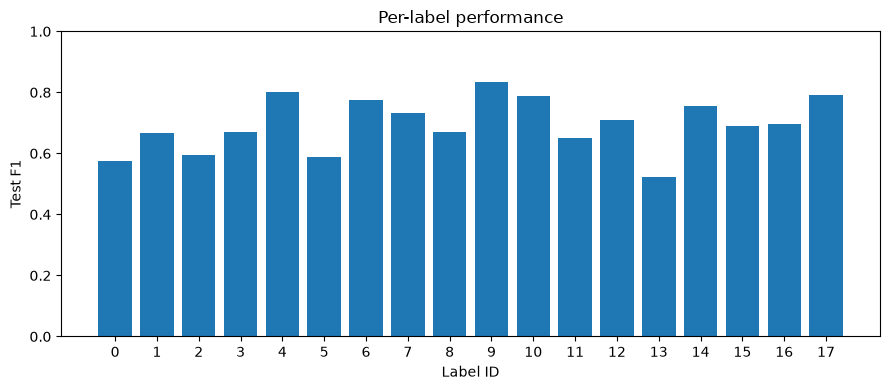

,label_id,TN,FP,FN,TP,precision,recall,f1,support
0,0,1480,26,74,68,0.723404,0.478873,0.576271,142
1,1,1430,70,39,109,0.608939,0.736486,0.666667,148
2,2,1478,28,70,72,0.720000,0.507042,0.595041,142
3,3,1430,70,38,110,0.611111,0.743243,0.670732,148
4,4,1486,9,45,108,0.923077,0.705882,0.800000,153
5,5,1482,24,73,69,0.741935,0.485915,0.587234,142
6,6,1418,49,35,146,0.748718,0.806630,0.776596,181
7,7,1274,90,68,216,0.705882,0.760563,0.732203,284
8,8,1461,27,66,94,0.776860,0.587500,0.669039,160
9,9,888,124,92,544,0.814371,0.855346,0.834356,636


In [11]:
counts = multilabel_confusion_matrix(Y_test, Y_pred)
confusion_per_label = pd.DataFrame({'label_id':np.arange(N_CLASSES),
    'TN':counts[:,0,0], 'FP':counts[:,0,1], 'FN':counts[:,1,0], 'TP':counts[:,1,1],
    'precision':precision_score(Y_test,Y_pred,average=None,zero_division=0),
    'recall':recall_score(Y_test,Y_pred,average=None,zero_division=0),
    'f1':f1_score(Y_test,Y_pred,average=None,zero_division=0),
    'support':Y_test.sum(axis=0)})
assert (counts.sum(axis=(1,2)) == len(test_idx)).all()
confusion_per_label.to_csv(REPORT_DIR / 'per_label_metrics.csv', index=False)
fig, ax = plt.subplots(figsize=(9,4))
ax.bar(confusion_per_label['label_id'],confusion_per_label['f1'])
ax.set(xlabel='Label ID',ylabel='Test F1',ylim=(0,1),title='Per-label performance')
ax.set_xticks(np.arange(N_CLASSES));fig.tight_layout()
fig.savefig(REPORT_DIR / 'per_label_f1.png', dpi=150);plt.show()
confusion_per_label

## Reproducibility and conclusions

Save the selected network, training vocabulary, scaler statistics, threshold, split assignments and measured results. Verify that loading the network preserves predictions. These files allow the same input preparation and inference for new entries with the supplied BoW representation. Raw news text, dataset and binary models are excluded from GitHub.

Interpret the training/validation gap alongside predictive performance: early stopping, dropout and L2 reduce fitting capacity but do not establish that overfitting is absent. Further limits include the supplied collection-wide BoW vocabulary, a single random split/seed, repeated validation use and no chronological or external-source test. The experiment does not establish which input branch contributes most.

In [12]:
model.save(REPORT_DIR / 'model.keras')
reloaded = tf.keras.models.load_model(REPORT_DIR / 'model.keras')
reloaded_prob = reloaded.predict([X_text_test[:32],X_bow_test[:32],X_meta_test[:32]],verbose=0)
np.testing.assert_allclose(reloaded_prob,Y_prob[:32],rtol=1e-5,atol=1e-6)
preprocessing = {'word_dict':word_dict,'padding_id':0,'unknown_id':1,
    'max_text_length':MAX_TEXT_LEN,'metadata_mean':metadata_scaler.mean_.tolist(),
    'metadata_scale':metadata_scaler.scale_.tolist(),'threshold':threshold}
(REPORT_DIR / 'preprocessing.json').write_text(json.dumps(preprocessing,indent=2))
np.savez_compressed(REPORT_DIR / 'test_predictions.npz',row_id=test_idx,y_true=Y_test,y_prob=Y_prob)
with PKL_PATH.open('rb') as f:
    dataset_hash = hashlib.file_digest(f,'sha256').hexdigest()
metadata = {'seed':SEED,'dataset_sha256':dataset_hash,
    'split_sizes':{'train':len(train_idx),'validation':len(val_idx),'test':len(test_idx)},
    'duplicate_extra_rows':len(texts)-len(set(groups)),
    'selected_config':best_config,'selected_best_epoch':int(tuning_results_df.iloc[best_index]['best_epoch']),
    'selected_gap_at_half':float(tuning_results_df.iloc[best_index]['gap']),
    'threshold':threshold,'test_metrics':metric_summary(Y_test,Y_pred),
    'python':platform.python_version(),'tensorflow':tf.__version__,
    'numpy':np.__version__,'pandas':pd.__version__,
    'runtime_seconds':time.perf_counter()-run_start,
    'protocol':'grouped 70/15/15 holdout; supplied BoW; training vocabulary/scaler; validation selection; internal test'}
(REPORT_DIR / 'run_metadata.json').write_text(json.dumps(metadata,indent=2))
for config in TUNING_CONFIGS: (REPORT_DIR / (config['name']+'.keras')).unlink()
print('Selected:',best_config['name'],'| Best epoch:',metadata['selected_best_epoch'])
print('Test macro-F1:',metadata['test_metrics']['macro_f1'])
print('Prediction equality after reload: verified')
shutil.make_archive('news_results','zip',REPORT_DIR)
print('Saved reports and news_results.zip')

Selected: stronger_dropout | Best epoch: 5
Test macro-F1: 0.6950846952240594
Prediction equality after reload: verified


Saved reports and news_results.zip
